# Step 1. Read

*With ngff-zarr.*

**Goal:** open two OME-Zarr images from a public archive, and read only what you need.

In [1]:
from pathlib import Path

import fsspec
import ngff_zarr as nz
import numpy as np
from common import overlay
from IPython.display import Image

OUTPUT = Path("../output")
OUTPUT.mkdir(exist_ok=True)

ARCHIVE = "https://zenodo.org/records/13982701/files/220605_151046.zarr.zip"
WELL = "220605_151046.zarr/C/02"

archive = fsspec.filesystem("zip", fo=fsspec.open(ARCHIVE).open())
rounds = {name: nz.from_ngff_zarr(archive.get_mapper(f"{WELL}/{i}")) for name, i in (("R0", 0), ("R1", 1))}

for name, multiscales in rounds.items():
    image = multiscales.images[0]
    size = " x ".join(str(image.data.shape[image.dims.index(axis)]) for axis in "zyx")
    voxel = " x ".join(f"{image.scale[axis]:.3g}" for axis in "zyx")
    print(f"{name}: {size} voxels of {voxel} {image.axes_units['x']}s, {len(multiscales.images)} levels")

R0: 50 x 680 x 535 voxels of 0.6 x 0.217 x 0.217 micrometers, 5 levels
R1: 50 x 680 x 535 voxels of 0.6 x 0.217 x 0.217 micrometers, 5 levels


**Opening an image reads almost nothing.** The images sit in a 38 MB zip on Zenodo, and ngff-zarr opened them where they are, from their metadata.

**An image is a pyramid with a geometry.** Each of the 5 levels knows its voxel size and its unit. The registration will use them: nothing here is in pixels.

**Reading is lazy.** `image.data` is a dask array, and only what you compute is read. Here, one plane of one level (dims c, z, y, x), of each round:

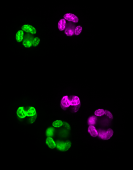

In [2]:
fixed_plane, moving_plane = (np.asarray(rounds[name].images[2].data[0, 25]) for name in ("R0", "R1"))
overlay(fixed_plane, moving_plane, OUTPUT / "before.png")
Image(OUTPUT / "before.png", width=340)

Green is round R0, magenta is round R1. The same organoid has moved between the two rounds, and the two colours do not overlap at all.

## Keep a local copy

The registration of step 2 reads local stores of one channel: a copy of both images, their DAPI channel alone, and of their nuclei for step 4. This cell reads from Zenodo, and takes a minute or two.

In [3]:
for name, i in (("R0", 0), ("R1", 1)):
    image = rounds[name].images[0]
    dapi = nz.NgffImage(
        data=image.data[0].persist(),  # 36 MB, read once: the pyramid is computed from it
        dims=["z", "y", "x"],
        scale={axis: image.scale[axis] for axis in "zyx"},
        translation={axis: image.translation[axis] for axis in "zyx"},
        axes_units={axis: image.axes_units[axis] for axis in "zyx"},
    )
    nz.to_ngff_zarr(OUTPUT / f"{name}.ome.zarr", nz.to_multiscales(dapi), version="0.5")
    nuclei = nz.from_ngff_zarr(archive.get_mapper(f"{WELL}/{i}/labels/nuc"))
    nz.to_ngff_zarr(OUTPUT / f"{name}_nuclei.ome.zarr", nuclei, version="0.5")

print(sorted(path.name for path in OUTPUT.glob("*.ome.zarr")))

['R0.ome.zarr', 'R0_nuclei.ome.zarr', 'R1.ome.zarr', 'R1_nuclei.ome.zarr']


**Next: [Step 2. Register](2-register.ipynb)**